# Penguin Species Classification Using Logistic Regression

## 1. Importing the necessary Libraries and Loading the Dataset

In [36]:
# Import Libraries
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

In [ ]:
# Load Dataset
penguin_dataset = pd.read_csv("../data/penguins_binary_classification.csv")
penguin_dataset.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,2007
3,Adelie,Torgersen,36.7,19.3,193.0,3450.0,2007
4,Adelie,Torgersen,39.3,20.6,190.0,3650.0,2007


In [6]:
penguin_dataset.head(20)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,2007
3,Adelie,Torgersen,36.7,19.3,193.0,3450.0,2007
4,Adelie,Torgersen,39.3,20.6,190.0,3650.0,2007
5,Adelie,Torgersen,38.9,17.8,181.0,3625.0,2007
6,Adelie,Torgersen,39.2,19.6,195.0,4675.0,2007
7,Adelie,Torgersen,34.1,18.1,193.0,3475.0,2007
8,Adelie,Torgersen,42.0,20.2,190.0,4250.0,2007
9,Adelie,Torgersen,37.8,17.1,186.0,3300.0,2007


## 2. Inspecting the Dataset

In [10]:
def basic_checks(data):
    print("="*25, "SHAPE", "="*25)
    print(data.shape)
    print("="*25, "COLUMN NAMES", "="*25)
    print(data.columns.to_list())
    print("="*25, "DATA TYPES", "="*25)
    print(data.dtypes)
    print("="*25, "MISSING VALUES", "="*25)
    print(data.isnull().sum())
    print("="*25, "DUPLICATES", "="*25)
    print(data.duplicated().sum())
    print("="*25, "NUMERICAL STATS", "="*25)
    display(data.describe().T)
    print("="*25, "UNIQUE VALUES", "="*25)
    print(data.nunique())

    # Categorical Columns Inspections
    print("="*25, "CATEGORICAL STATS", "="*25)
    display(data.describe(include="str").T)

    for col in data.select_dtypes(include="str").columns:
        print(f"\n{col}")
        print(data[col].value_counts())


In [11]:
basic_checks(penguin_dataset)

========================= SHAPE =========================
(274, 7)
========================= COLUMN NAMES =========================
['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'year']
========================= DATA TYPES =========================
species                  str
island                   str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
year                   int64
dtype: object
========================= MISSING VALUES =========================
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
year                 0
dtype: int64
========================= DUPLICATES =========================
0
========================= NUMERICAL STATS =========================


,count,mean,std,min,25%,50%,75%,max
bill_length_mm,274.0,42.702920,5.195566,32.1,38.35,42.0,46.675,59.6
bill_depth_mm,274.0,16.836131,2.013410,13.1,15.00,17.0,18.500,21.5
flipper_length_mm,274.0,202.178832,15.047938,172.0,190.00,198.0,215.000,231.0
body_mass_g,274.0,4318.065693,835.933105,2850.0,3600.00,4262.5,4950.000,6300.0
year,274.0,2008.043796,0.806281,2007.0,2007.00,2008.0,2009.000,2009.0


========================= UNIQUE VALUES =========================
species                2
island                 3
bill_length_mm       146
bill_depth_mm         78
flipper_length_mm     54
body_mass_g           89
year                   3
dtype: int64
========================= CATEGORICAL STATS =========================


,count,unique,top,freq
species,274,2,Adelie,151
island,274,3,Biscoe,167



species
species
Adelie    151
Gentoo    123
Name: count, dtype: int64

island
island
Biscoe       167
Dream         56
Torgersen     51
Name: count, dtype: int64


# 3. Defining Features and Target

In [7]:
X = penguin_dataset.drop(columns=["species", "year"])
y = penguin_dataset["species"]

## 4. Splitting the Train and Test Data


In [ ]:
# Splitting the train and test data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y, 
    test_size=0.2, 
    stratify=y, 
    random_state=42)

In [14]:
# Verifying target class distribution
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

species
Adelie    0.552511
Gentoo    0.447489
Name: proportion, dtype: float64
species
Adelie    0.545455
Gentoo    0.454545
Name: proportion, dtype: float64


In [15]:
# Verifying sizes of the split data
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(219, 5)
(55, 5)
(219,)
(55,)


## 5. Preprocessing

In [17]:
# Checking the training data
X_train.head()

,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
247,Biscoe,49.4,15.8,216.0,4925.0
140,Dream,40.6,17.2,187.0,3475.0
95,Dream,38.1,18.6,190.0,3700.0
170,Biscoe,48.7,15.1,222.0,5350.0
148,Dream,37.8,18.1,193.0,3750.0


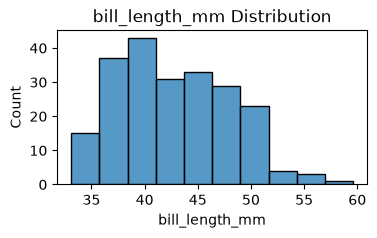

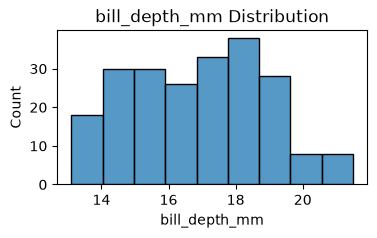

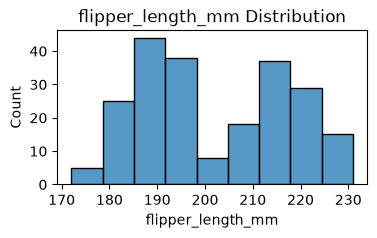

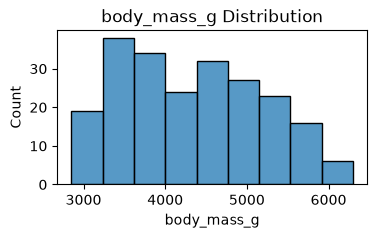

In [27]:
# Checking Distribution of Numerical columns
numerical_columns = X_train.select_dtypes(include=["int", "float"]).columns

for col in numerical_columns:

    plt.figure(figsize=(4,2))
    sns.histplot(X_train[col])

    plt.xlabel(col)
    plt.ylabel("Count")
    plt.title(f"{col} Distribution")
    plt.show()
    

In [29]:
# Creating Preprocessing Pipelines
# island column encoder
island_pipeline = Pipeline([("encoder", OneHotEncoder(drop="first", handle_unknown="ignore"))])

# Numerical columns scaling
numerical_col_pipeline = Pipeline([("scaler", StandardScaler())])

# Column transformer for the multiple pipelines
preprocessing = ColumnTransformer([
    ("island_pipeline", island_pipeline, ["island"]),
    ("numerical_pipeline", numerical_col_pipeline, numerical_columns)
    ])

# Creating the main pipeline
main_pipeline = Pipeline([("preprocessing", preprocessing),
                 ("model", LogisticRegression())
                 ])

## 6. Training the Model via the main_pipeline

In [ ]:
# Train the baseline model
main_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['Adelie','Gentoo']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['island','bill_length_mm','bill_depth_mm','flipper_length_mm', 'body_mass_g']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('island_pipeline', ...), ('numerical_pipeline', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``)

## 7. Generate Predictions from the Baseline Model

In [31]:
y_train_pred = main_pipeline.predict(X_train)
y_test_pred = main_pipeline.predict(X_test)

## 8. Calculating Baseline Model Metrics

In [34]:
# Metrics on training data

print("Accuracy:", accuracy_score(y_train, y_train_pred))
print("Precision:", precision_score(y_train, y_train_pred, pos_label="Adelie"))
print("Recall:", recall_score(y_train, y_train_pred, pos_label="Adelie"))
print("F1 Score:", f1_score(y_train, y_train_pred, pos_label="Adelie"))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


In [35]:
# Metrics on test data

print("Accuracy:", accuracy_score(y_test, y_test_pred))
print("Precision:", precision_score(y_test, y_test_pred, pos_label="Adelie"))
print("Recall:", recall_score(y_test, y_test_pred, pos_label="Adelie"))
print("F1 Score:", f1_score(y_test, y_test_pred, pos_label="Adelie"))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


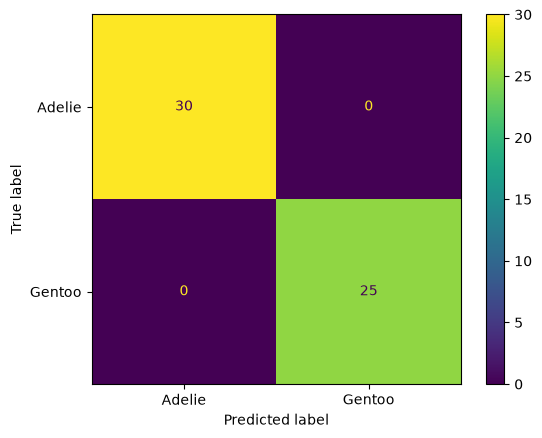

In [39]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=main_pipeline.classes_
)

disp.plot()
plt.show()